In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
tsb_ad = pd.read_csv(
    "../results/TSB-AD/uni_mergedTable_VUS-PR.csv", index_col="file"
).drop(
    columns=[
        "ts_len",
        "anomaly_len",
        "num_anomaly",
        "avg_anomaly_len",
        "anomaly_ratio",
        "point_anomaly",
        "seq_anomaly",
    ]
)
tsb_ad.head()

,Sub-IForest,IForest,Sub-LOF,LOF,POLY,MatrixProfile,KShapeAD,SAND,Series2Graph,SR,...,USAD,Donut,TimesNet,FITS,OFA,Lag-Llama,Chronos,TimesFM,MOMENT (ZS),MOMENT (FT)
file,,,,,,,,,,,,,,,,,,,,,
001_NAB_id_1_Facility_tr_1007_1st_2014.csv,0.085606,0.135409,0.140321,0.138739,0.261176,0.093966,0.090861,0.084533,0.194310,0.134766,...,0.124323,0.126143,0.220694,0.349750,0.296445,0.129903,0.147666,0.148769,0.572437,0.573612
002_NAB_id_2_WebService_tr_1500_1st_4106.csv,0.082171,0.148399,0.118864,0.138218,0.625950,0.080120,0.064706,0.146175,0.573108,0.144111,...,0.402065,0.108775,0.176204,0.270327,0.148986,0.135834,0.136280,0.137582,0.339768,0.340660
005_NAB_id_5_Traffic_tr_594_1st_1645.csv,0.095674,0.117981,0.058892,0.106432,0.163865,0.090439,0.099001,0.289604,0.117060,0.103600,...,0.113087,0.104470,0.105885,0.141246,0.097450,0.100193,0.089370,0.099484,0.128709,0.126756
006_NAB_id_6_Traffic_tr_2579_1st_5839.csv,0.362309,0.159264,0.661446,0.155025,0.246658,0.704054,0.840598,0.570772,0.401304,0.130987,...,0.088079,0.135515,0.114821,0.110137,0.097697,0.110638,0.129708,0.114509,0.091797,0.097552
008_NAB_id_8_Synthetic_tr_1007_1st_2734.csv,0.749318,0.240052,0.771611,0.120385,0.796120,0.736019,0.774015,0.714066,0.683984,0.438581,...,0.831536,0.340749,0.532024,0.418502,0.476098,0.338958,0.259855,0.341389,0.794463,0.793288


In [4]:
def compare(method_name: str):
    data = [
        pd.read_csv(f"../results/TSB-AD/reproduced/{method_name}.csv")["VUS-PR"],
        tsb_ad[method_name],
    ]

    plt.figure(figsize=(12, 2))

    plt.boxplot(
        data,
        tick_labels=["Reproduced", "Original"],
        orientation="horizontal",
        widths=0.8,
    )
    plt.title(f"Comparison of VUS-PR for {method_name}")
    plt.ylabel("VUS-PR")

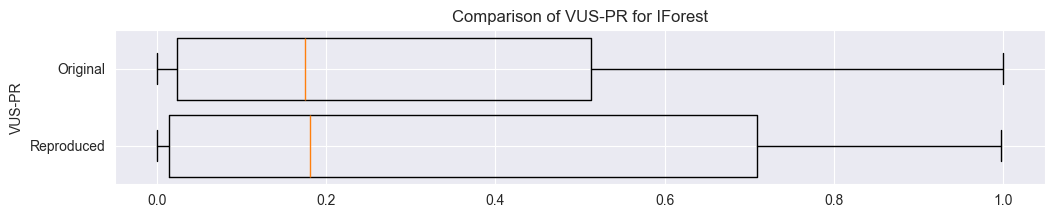

In [5]:
compare("IForest")

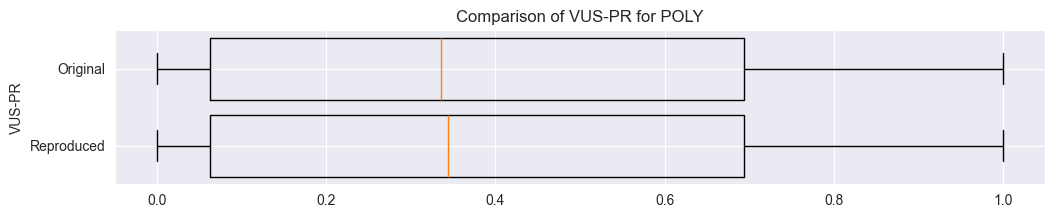

In [6]:
compare("POLY")

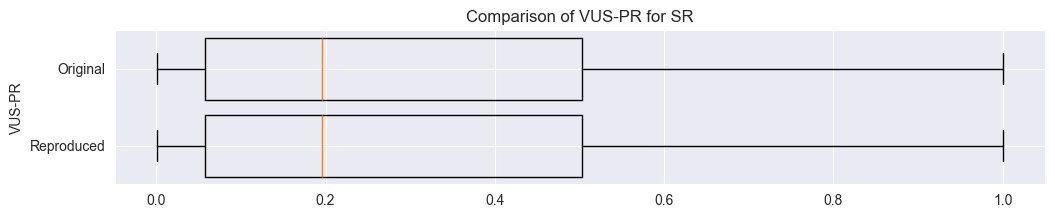

In [7]:
compare("SR")

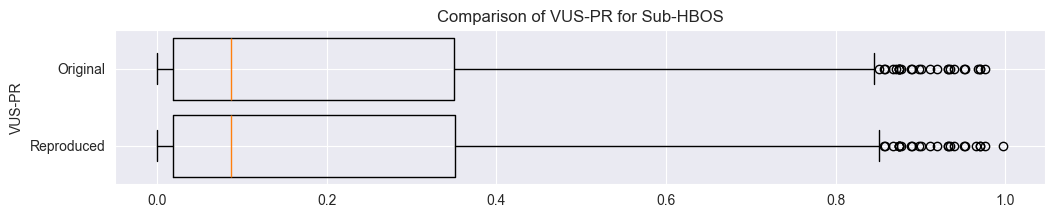

In [8]:
compare("Sub-HBOS")

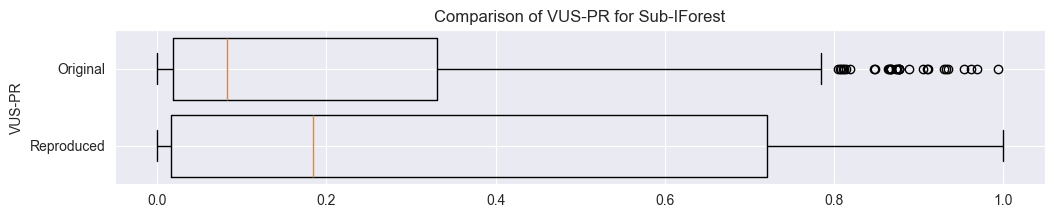

In [9]:
compare("Sub-IForest")

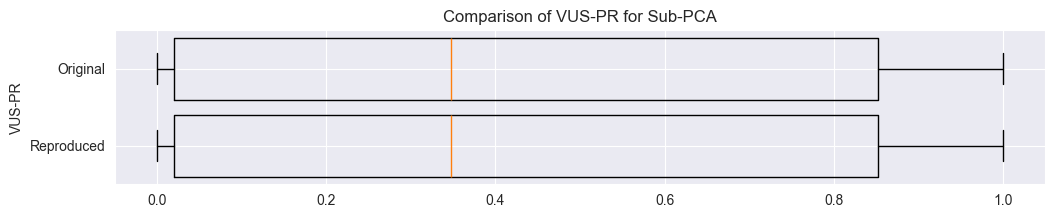

In [10]:
compare("Sub-PCA")

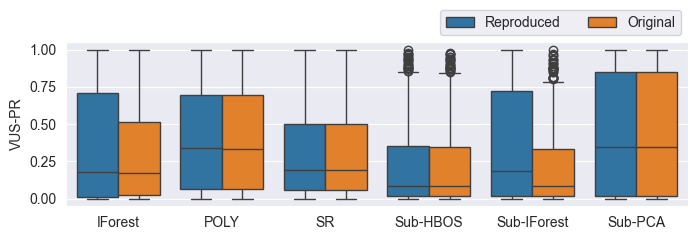

In [33]:
def compare_multiple(method_names: list[str]):
    data = []
    for method_name in method_names:
        reproduced = pd.read_csv(f"../results/TSB-AD/reproduced/{method_name}.csv")[
            "VUS-PR"
        ]
        original = tsb_ad[method_name]
        data.append(
            pd.DataFrame(
                {
                    "VUS-PR": pd.concat([reproduced, original], ignore_index=True),
                    "Method": [method_name] * (len(reproduced) + len(original)),
                    "Type": ["Reproduced"] * len(reproduced)
                    + ["Original"] * len(original),
                }
            )
        )

    combined_data = pd.concat(data, ignore_index=True)

    fig = plt.figure(figsize=(7, 2.5))
    sns.boxplot(x="Method", y="VUS-PR", hue="Type", data=combined_data)
    plt.ylabel("VUS-PR")
    plt.xlabel("")
    plt.legend(title="", loc="lower right", bbox_to_anchor=(1.0, 1.0), ncols=2)
    fig.tight_layout()
    return fig


f = compare_multiple(["IForest", "POLY", "SR", "Sub-HBOS", "Sub-IForest", "Sub-PCA"])
f.savefig("figures/fig-reproduce-tsb-ad.png", bbox_inches="tight")